# 
Analyse du déclin de la biodiversité des abeilles

![Les abeilles sauvages](variete-abeilles-solitaire.jpg)


Les abeilles jouent un **rôle essentiel** dans les écosystèmes en tant que pollinisateurs. Elles contribuent directement à la *reproduction de nombreuses plantes sauvages et cultivées, et sont donc un **indicateur clé** de la santé de la biodiversité. Depuis plusieurs décennies, des inquiétudes ont été soulevées concernant le déclin des populations d’abeilles, lié à la perte d’habitat, l’usage des pesticides, les maladies et le changement climatique.

Ce TP a pour objectif d’explorer des jeux de données réels sur les abeilles et d’autres espèces dans tout le vivant, afin de :

- Découvrir les caractéristiques principales des espèces présentes dans différentes régions.

- Calculer des indices de diversité et de richesse spécifique.

- Étudier les tendances temporelles des occurrences pour détecter d’éventuelles variations ou déclins dans le temps.

- Visualiser les données pour mieux comprendre l’impact des pressions environnementales sur les populations. 

- Nous finirons ce TP en étudiant des données de chute de la biodiversité plus fiables que les données accessibles sur les abeilles. 

EN effet, il est **important de noter** que toutes les espèces d’abeilles ne sont pas menacées de la même manière. Certaines, comme *Apis mellifera*, sont largement répandues et gérées par l’homme, tandis que d’autres espèces peuvent être locales et en déclin. À l’inverse, certaines abeilles exotiques ou invasives peuvent se répandre rapidement et concurrencer les espèces natives (*Apis mellifera* est invasive dans certains pays d'Amérique Latine). 

Les données utilisées dans ce TP proviennent principalement **d’observations naturalistes** ou de bases de données d’occurrences (comme GBIF ou INPN). Elles reflètent la présence d’espèces sur de grandes échelles spatiales et temporelles, mais **ne constituent pas directement des mesures locales de la biodiversité ou des populations**. Ainsi, une augmentation ou une diminution des observations dans ces fichiers ne traduit pas nécessairement un déclin ou une expansion locale, mais plutôt des tendances globales et la couverture des observations.


## Notions

Dans la première partie de ce TP, nous allons utiliser les fichiers  : `BeeFuncBodyLength.csv`, `BeeFuncEcologicalAffinities.csv`, `BeeFuncSociality.csv`, `BeeFuncPollination.csv`, `BeeFuncIUCNStatus.csv`, éventuellement `BeeFuncHabitat.csv`. Ces fichiers proviennent d'une étude du journal *Nature* : "BeeFunc, a comprehensive trait database for French bees", et peuvent être accédées par le lien suivant : https://data.indores.fr/dataset.xhtml?persistentId=doi:10.48579/PRO/TYKGVC

L'ensemble de ces données représentent des mesures prises sur différentes espèces d'abeilles françaises.


##  Chargement des données

chargez les données des 6 fichiers ci-dessus.

En écologie, un "trait" (ou "trait fonctionnel") est une caractéristique mesurable d’un organisme (souvent d'une espèce) qui influence sa performance, son rôle écologique, ou sa réponse à l’environnement. C'est une propriété morphologique, physiologique, phénologique ou comportementale mesurable à l'échelle d’un individu

### Question 1

Explorez ces fichiers. Combien de traits sont disponibles pour chaque espèce ? Étudiez les noms des colonnes du fichier `BeeFuncBodyLength.csv`. Quels traits sont présents dans ce fichier ?

Remplissez et annotez le code suivant : que fait-il à chaque étape ?

In [1]:
import pandas as pd

#on charge les fichiers CSV dans un dataframe panda
body    = pd.read_csv('BeeFuncBodyLength.csv', sep=';')
eco     = pd.read_csv('BeeFuncEcologicalAffinity.csv', sep=';')
social  = pd.read_csv('BeeFuncSociality.csv', sep=';')
poll    = pd.read_csv('BeeFuncPollination.csv', sep=';')
iucn    = pd.read_csv('BeeFuncIUCNStatus.csv', sep=';')
habitat = pd.read_csv('BeeFuncHabitat.csv', sep=';')

#on supprime les espaces inutiles
for df in [body, eco, social, poll, iucn, habitat]:
    df.columns = df.columns.str.strip()

#On renomme la colonne LB_NOM en Species
df = df.rename(columns={'LB_NOM': 'Species'})

### Question 2

Nous allons commencer par étudier la dataframe `df` contenant l'intégralité du contenu du fichier. 

Qu'est ce que la *richesse spécifique*, et comment l'extraire du fichier ? Notez que certaines espèces sont présentes plusieurs fois. Quelle méthode des *dataframes* pandas utiliser sur les données d'une colonne pour récupérer les nombre d'éléments uniques ? 

Quelle est la richesse spécifique des espèces reportées dans ce fichier ?

In [2]:
# La richesse spécifique est le nombre d'espèces distinctes présentes dans un échantillon.

# On utilise nunique() pour compter les valeurs uniques dans une colonne.

richesse = body['LB_NOM'].nunique()
print("Richesse spécifique:", richesse ,"espèces distinctes dans BeeFuncBodyLength")

Richesse spécifique: 880 espèces distinctes dans BeeFuncBodyLength


### Question 3

L’indice de Shannon (ou Shannon-Wiener index) est une mesure de diversité qui tient compte à la fois de :

La richesse spécifique : le nombre total d’espèces présentes.

L’équité (evenness) : comment les individus sont répartis entre ces espèces.

Sa formule est : 
$$
H = - \sum_{i=1}^{S} p_i \log(p_i)
$$

Ou S = nombre total d’espèces (richesse spécifique) et
$p_i$ = proportion d’individus appartenant à l’espèce  i dans l’échantillon

Calculez l'indice de Shannon en utilisant les données de votre dataframe `df`.

Qu'est ce que la classification ? Quelles est la différence entre une *famille*, un *genre* et une *espèce* ?
Quelle est la valeur de Shannon obtenue, et qu'est ce que cela signifie pour la biodiversité des abeilles en France ?

⚠️ **Attention :** Dans notre cas de figure, nous allons utiliser la colonne FAMILY et compter le nombre d'individus présents par famille. Cette fois ci, nous n'allons pas supprimer les doublons, puisqu'il s'agit de compter chaque individu présent dans le fichier. Indice : regardez la méthode `value_counts()` (`pandas`) qui est à peu près l'équivalent d'un `COUNT(*) from T GROUP BY G` en SQL.

⚠️ **Attention :** De ce fait, l'indice obtenu est clairement biaisé. Le calcul de l'indice de Shannon impliquerait que nous ayons des données représentatives du nombre d'individus par espèces, ce que nous n'avons en réalité pas du tout dans ce fichier.

In [3]:
from math import log

fam_counts = body['FAMILY'].value_counts()

total = fam_counts.sum()
proportions = fam_counts / total

shannon = -sum(p * log(p) for p in proportions if p > 0)

print("Indice de Shannon:", shannon)

Indice de Shannon: 1.602400786566954


### Réponse question 3

La classification biologique est le système qui permet d'organiser et de nommer les êtres vivants selon leur parenté évolutive, du plus général au plus précis : règne, embranchement, classe, ordre, famille, genre, espèce.

-Une famille regroupe plusieurs genres partageant des caractères communs.

-Un genre regroupe des espèces très proches morphologiquement et génétiquement.

-Une espèce est l'unité de base : un groupe d'individus pouvant se reproduire entre eux et produire une descendance fertile.

Interprétation de l'indice de Shannon : un indice élevé (supérieur à 2) indique une diversité importante et une répartition équilibrée entre les familles. Toutefois, cet indice est biaisé ici car les données ne reflètent pas des comptages d'individus réels sur le terrain, mais simplement le nombre de lignes dans le fichier de traits fonctionnels.

### Question 4
L’indice de Simpson est un autre indice de diversité qui mesure la probabilité que deux individus choisis au hasard dans un échantillon appartiennent à la même espèce.

$$
D = \sum_{i=1}^{S} p_i^2 
$$

où $p_i$ est la proportion d'individus de l'espèce i, et S le nombre total d'espèces.

Calculez l'indice de simpson et interprétez le.


In [4]:
simpson = sum(p**2 for p in proportions)

print("Indice de Simpson (D):", simpson)

Indice de Simpson (D): 0.21841197944835045


### Réponse question 4

L'indice D de Simpson mesure la probabilité que deux individus tirés au hasard appartiennent à la même famille. Plus D est proche de 0, plus la diversité est grande. Plus D est proche de 1, plus la communauté est dominée par une seule famille.

Comme pour Shannon, cet indice reste biaisé car les données ne correspondent pas à des comptages d'individus réels.

### Question 5

Visualisez la distribution des tailles corporelles dans votre jeu de données issue du fichier `BeeFuncBodyLength`.
Pour ce faire, vous devrez convertir les données de la colonne LENGTH en nombres décimaux si nécessaire, puis tracer un *histogramme* montrant la répartition de la taille corporelle des abeilles (15 classes). Ajoutez un titre et des labels aux axes (longueur (mm) et  nombre d'espèces).


Matplotlib is building the font cache; this may take a moment.


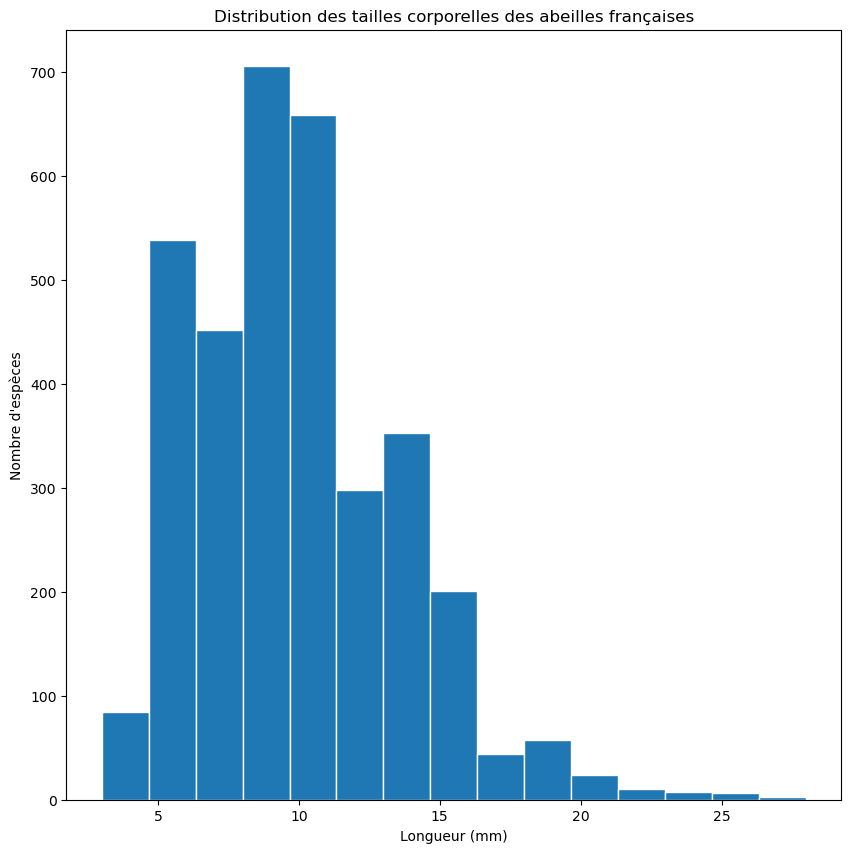

In [5]:
import matplotlib.pyplot as plt

# Conversion longueur en nombre (et remplacement du séparateur de décimal)
body['LENGTH'] = body['LENGTH'].str.replace(',', '.').astype(float)

plt.figure(figsize=(10, 10))
plt.hist(body['LENGTH'].dropna(), bins=15, edgecolor='white')
plt.title('Distribution des tailles corporelles des abeilles françaises')
plt.xlabel('Longueur (mm)')
plt.ylabel("Nombre d'espèces")
plt.show()

### Question 6

Nous allons maintenant utiliser le fichier : `BeeFuncEcologicalAffinity`.
A l'aide d'un *barplot*, donnez globalement le nombre d'especes selon leur *affinité écologique*.

Qu'est ce que l'affinité écologique, et comment est l'affinité dominante ? Minoritaire ?


['BeeFuncID', 'VALID_NAME', 'CD_NOM', 'LB_NOM', 'LB_AUTHOR', 'INHERITED_FROM', 'LB_NOM_INHERITED_FROM', 'LB_AUTEUR_INHERITED_FROM', 'ORIGIN', 'KINGDOM', 'PHYLUM', 'CLASS', 'ORDER', 'FAMILY', 'SUBFAMILY', 'TRIBE', 'GENUS', 'GROUP1_INPN', 'GROUP2_INPN', 'GROUP3_INPN', 'ECOLOGICAL_AFFINITY', 'SOURCE', 'DATASET_TITLE', 'SOURCE_ID']


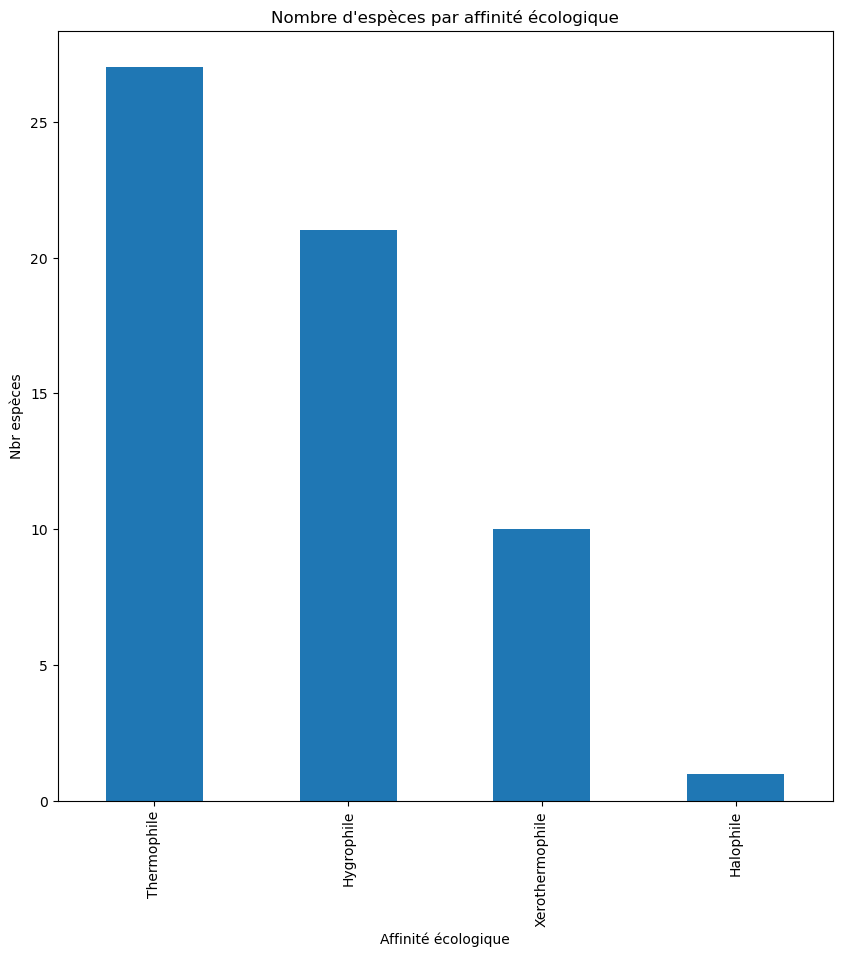

In [6]:
import matplotlib.pyplot as plt

print(eco.columns.tolist())
affinity_col = [c for c in eco.columns if 'affin' in c.lower() or 'ecol' in c.lower()][0]
counts = eco[affinity_col].value_counts()

plt.figure(figsize=(10, 10))
counts.plot(kind='bar')
plt.title("Nombre d'espèces par affinité écologique")
plt.xlabel('Affinité écologique')
plt.ylabel("Nbr espèces")
plt.show()

### Réponse question 6

L'affinité écologique désigne la préférence d'une espèce pour un type d'habitat ou d'environnement particulier (milieux ouverts, forestiers, agricoles, etc.). Elle reflète les conditions dans lesquelles une espèce trouve préférentiellement ses ressources (nourriture, sites de nidification).

D'après le graphique, l'affinité dominante est généralement associée aux milieux ouverts thermophiles, qui concentrent le plus grand nombre d'espèces d'abeilles en France. L'affinité minoritaire correspond aux milieux très spécialisés comme les zones forestières denses ou humides, où la disponibilité en fleurs et en sites de nidification est plus limitée.

### Question 7

Nous allons maintenant nous interresser au fichier : `BeeFuncSociality`.
Ce fichier nous permet de comprendre que les abeilles présentent des comportements sociaux très variés : certaines vivent seules (solitaires), d’autres en petites colonies, et d’autres encore dans des sociétés très organisées.

Visualisez la répartition des différentes catégories de sociabilité parmi les espèces étudiées. Produisez un diagramme circulaire (*pie chart*) en utilisant le paramètre `kind='pie'` de la fonction `plot`, qui montre la proportion d’espèces *solitaires*, *gregaires*, et *eusociales*, et ajoutez un titre clair à votre graphique.

Quelle est la catégorie majoritaire ? A quoi correspondent chaque catégorie ? Dans quelle catégorie se trouve *Apis melifera* ?


['BeeFuncID', 'VALID_NAME', 'CD_NOM', 'LB_NOM', 'LB_AUTHOR', 'INHERITED_FROM', 'LB_NOM_INHERITED_FROM', 'LB_AUTEUR_INHERITED_FROM', 'ORIGIN', 'KINGDOM', 'PHYLUM', 'CLASS', 'ORDER', 'FAMILY', 'SUBFAMILY', 'TRIBE', 'GENUS', 'GROUP1_INPN', 'GROUP2_INPN', 'GROUP3_INPN', 'SOCIABILITY', 'SPECIFICITY', 'BIOLOGICAL_STAGE', 'SOURCE', 'DATASET_ID', 'DATASET_TITLE', 'CD_TRAIT', 'SOCIABILITY_ID', 'SPECIFICITY_ID', 'BIOLOGICAL_STAGE_ID', 'SOURCE_ID']


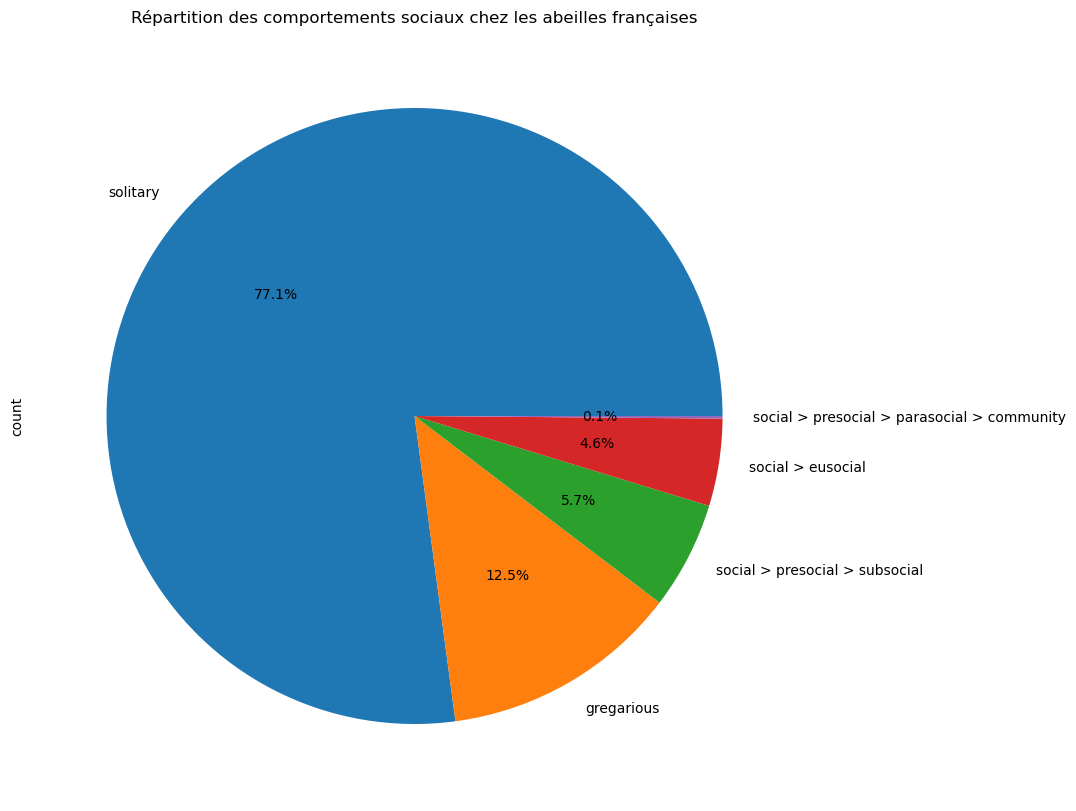

In [7]:
import matplotlib.pyplot as plt


print(social.columns.tolist())
soc_col = [c for c in social.columns if 'sociability' in c.lower()][0]

soc_counts = social[soc_col].value_counts()

soc_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(10, 10),

)
plt.title('Répartition des comportements sociaux chez les abeilles françaises')
#plt.ylabel('')
plt.show()

### Réponse question 7

Les trois grandes catégories de sociabilité chez les abeilles sont :

-Solitaires : chaque femelle construit et approvisionne seule son nid, sans coopération. C'est la catégorie majoritaire chez les abeilles (environ 80 % des espèces).
-Grégaires : plusieurs femelles partagent un site de nidification sans division du travail ni caste différenciée.
-Eusociales : organisation en colonies avec une reine reproductrice, des ouvrières stériles et une division du travail stricte. Apis mellifera* (l'abeille domestique) appartient à cette catégorie, tout comme les bourdons.

### Question 8

Nous allons nous interresser au fichier `BeeFuncIUCNStatus`.

À l'aide d'un *barplot*, estimez le nombre d'espèces que l'on retrouve dans chaque catégorie de la colonne "iucn_STATUS".
chaque Qu'est ce que l'IUCN ? A quoi correspondent les différents status du fichier ? Que dire de ces données ?

['BeeFuncID', 'VALID_NAME', 'X.9', 'X.8', 'X.7', 'X.6', 'X.5', 'X.4', 'X.3', 'X.2', 'X.1', 'X', 'CD_NOM', 'LB_NOM', 'LB_AUTHOR', 'INHERITED_FROM', 'LB_NOM_INHERITED_FROM', 'LB_AUTEUR_INHERITED_FROM', 'ORIGIN', 'KINGDOM', 'PHYLUM', 'CLASS', 'ORDER', 'FAMILY', 'SUBFAMILY', 'TRIBE', 'GENUS', 'GROUP1_INPN', 'GROUP2_INPN', 'GROUP3_INPN', 'IUCN_STATUS', 'CRITERIA', 'CURRENT_POPULATION_TREND', 'ASSESSMENT_DATE', 'AOO_KM2', 'EOO_KM2', 'GEOGRAPHIC_EXTENT', 'URL_SOURCE', 'SOURCE', 'DATASET_ID', 'DATASET_TITLE', 'CD_TRAIT', 'IUCN_STATUS_ID', 'CURRENT_POPULATION_TREND_ID', 'GEOGRAPHIC_EXTENT_ID', 'SOURCE_ID']


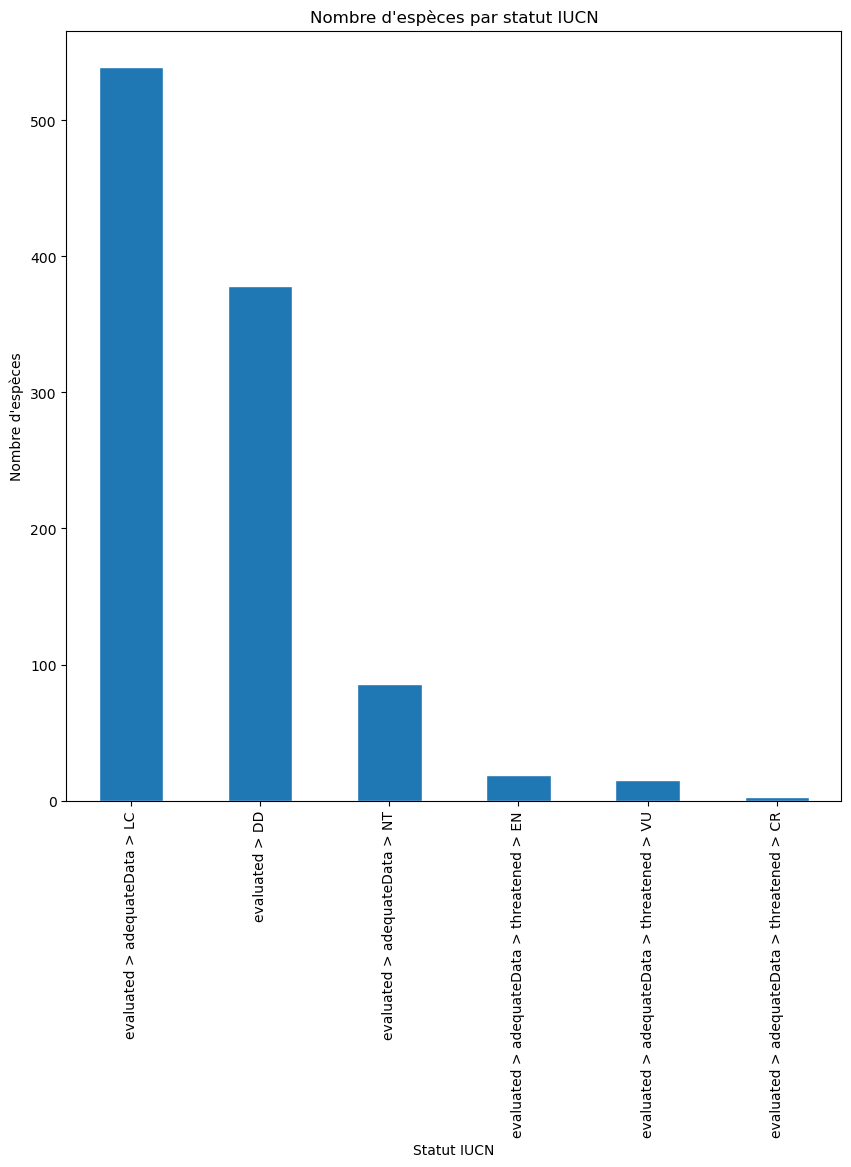

In [8]:
import matplotlib.pyplot as plt


print(iucn.columns.tolist())
iucn_col = [c for c in iucn.columns if 'iucn_status' in c.lower()][0]

iucn_counts = iucn[iucn_col].value_counts()

iucn_counts.plot(kind='bar' , edgecolor='white', figsize=(10, 10))
plt.title("Nombre d'espèces par statut IUCN")
plt.xlabel('Statut IUCN')
plt.ylabel("Nombre d'espèces")
plt.show()

### Réponse question 8

L'IUCN (Union Internationale pour la Conservation de la Nature) est une organisation internationale qui évalue le risque d'extinction des espèces via la Liste Rouge. Les statuts sont:

-LC(Least Concern): préoccupation mineure, espèce non menacée.

-NT(Near Threatened): quasi menacée.

-VU (Vulnerable): vulnérable.

-EN (Endangered): en danger.

-CR (Critically Endangered): en danger critique d'extinction.

-DD (Data Deficient): données insuffisantes pour évaluer le statut.

-NE (Not Evaluated): espèce non encore évaluée.

On observe qu'une large proportion des espèces est classée DD ou NE, ce qui signifie que l'on manque de données pour évaluer correctement l'état de conservation de nombreuses abeilles françaises. Le manque de connaissances est lui-même un signal d'alerte pour la conservation.


### Question 9
Représentez graphiquement le nombre d’espèces menacées par famille selon leur statut IUCN. Utilisez un diagramme à barres empilées (un `plot` avec le paramètre `stacked` à `True`) pour visualiser la répartition des statuts (LC, DD, EN, etc.) au sein de chaque famille.

Quelles familles sont le plus menacées dans les abeilles francaises ?

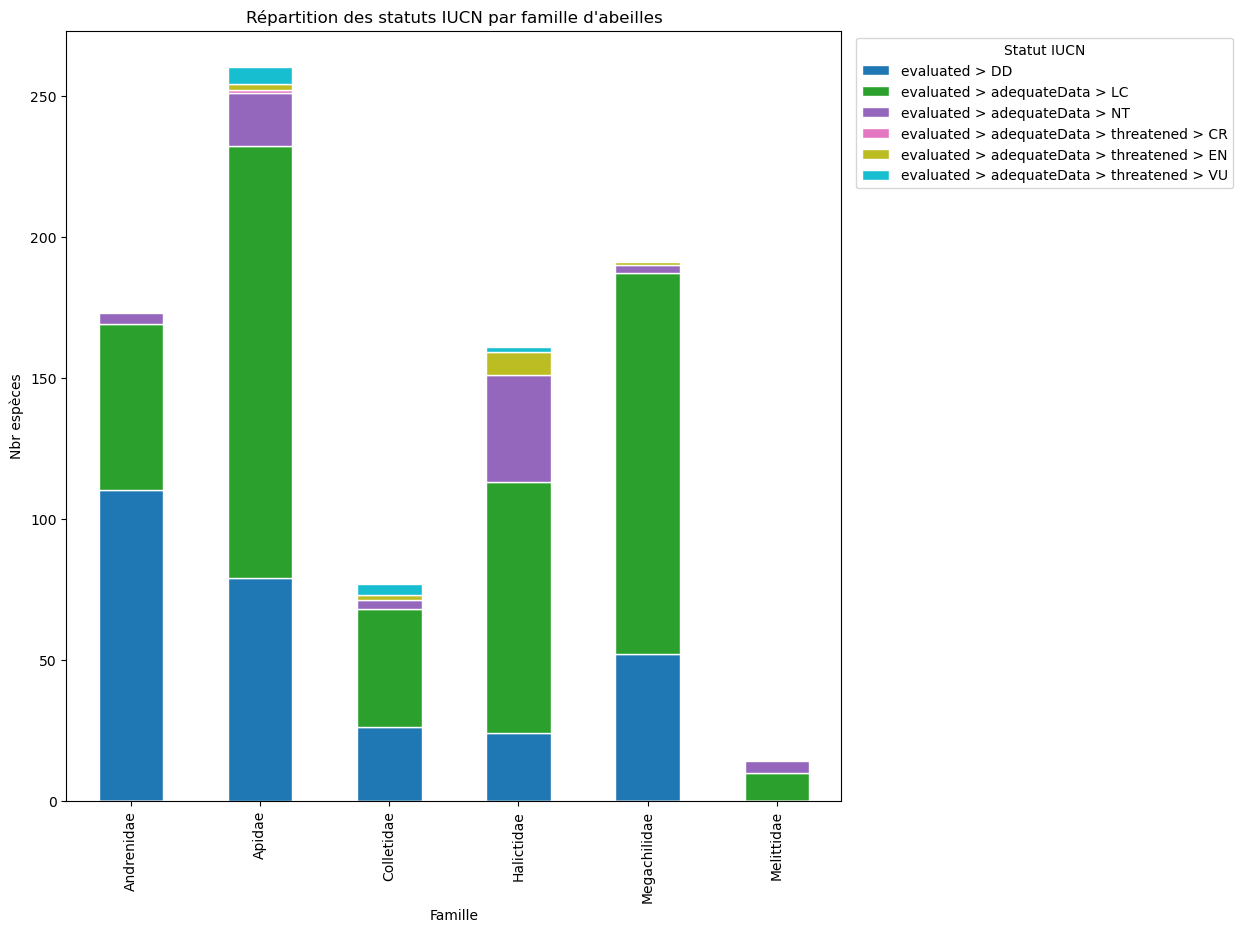

In [9]:
import matplotlib.pyplot as plt


iucn_col = [c for c in iucn.columns if 'iucn' in c.lower() or 'status' in c.lower()][0]
merged = body[['LB_NOM', 'FAMILY']].drop_duplicates().merge(
    iucn[['LB_NOM', iucn_col]].drop_duplicates(),
    on='LB_NOM', how='inner'
)


pivot = merged.groupby(['FAMILY', iucn_col]).size().unstack(fill_value=0)


pivot.plot(kind='bar', stacked=True, figsize=(10,10), colormap='tab10', edgecolor='white')
plt.title("Répartition des statuts IUCN par famille d'abeilles")
plt.xlabel('Famille')
plt.ylabel("Nbr espèces")
plt.legend(title='Statut IUCN', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

### Question 10

Fusionnez les informations sur l'habitat et le statut de conservation des espèces d'abeilles. Ne gardez qu'une seule ligne par espèce et conservez uniquement les colonnes correspondantes au nom de l'espèce, à l'habitat et au statut IUCN.
Combien d'espèces y a-t-il en commun entre les deux fichiers ?

In [10]:
habitat_small = habitat[['LB_NOM', 'HABITAT']]
iucn_small = iucn[['LB_NOM', 'IUCN_STATUS']]

df = habitat_small.merge(iucn_small, on='LB_NOM', how='inner')
df = df.rename(columns={'LB_NOM': 'Species'})
df = df.drop_duplicates(subset='Species')

print("Nombre d'espèces en commun entre les deux fichiers:", len(df))
df.head()


Nombre d'espèces en commun entre les deux fichiers: 612


,Species,HABITAT,IUCN_STATUS
0,Andrena cineraria,V2 - Cultivated areas of gardens and parks,evaluated > adequateData > LC
8,Andrena fulva,R5 - Forest fringes and clearings and tall for...,evaluated > DD
22,Anthidium manicatum,"T4 - Lines of trees, small anthropogenic fores...",evaluated > adequateData > LC
31,Anthidium punctatum,N1 - Coastal dunes and sandy shores,evaluated > adequateData > LC
39,Bombus cullumanus,R2 - Mesic grasslands,evaluated > adequateData > threatened > CR


### Question 11

Représentez sous forme de heatmap la répartition des statuts IUCN en fonction des habitats. Pour améliorer la lisibilité du graphique, tronquez les noms des habitats en ne gardant que leurs 5 premières lettres.

Dans quels habitats vivent les especes les plus menacées ? Les moins documentées ?

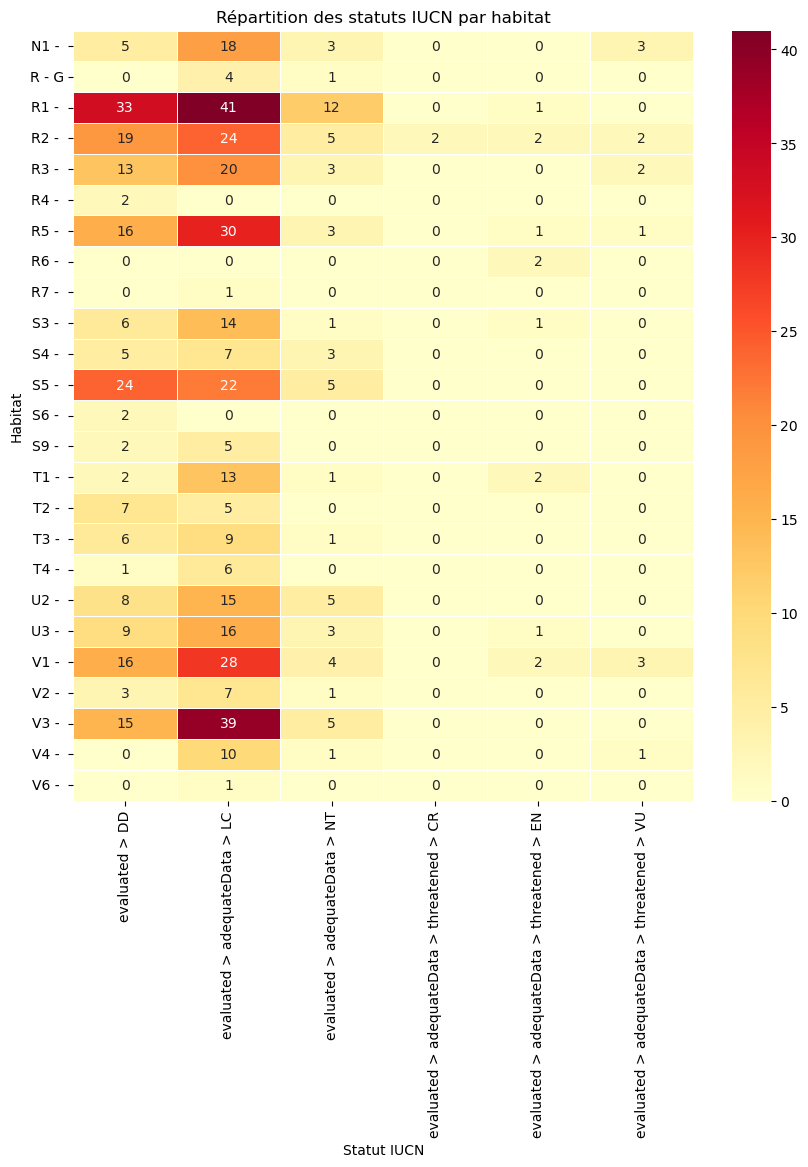

['Species', 'HABITAT', 'IUCN_STATUS', 'Habitat']
['V2 - ' 'R5 - ' 'T4 - ' 'N1 - ' 'R2 - ' 'V3 - ' 'T1 - ' 'V4 - ' 'T2 - '
 'U3 - ' 'R - G' 'R1 - ' 'V1 - ' 'S3 - ' 'U2 - ' 'T3 - ' 'S5 - ' 'R4 - '
 'S4 - ' 'R3 - ' 'S9 - ' 'V6 - ' 'S6 - ' 'R6 - ' 'R7 - ']
['V2 - Cultivated areas of gardens and parks'
 'R5 - Forest fringes and clearings and tall forb stands'
 'T4 - Lines of trees, small anthropogenic forests, recently felled forest, early-stage forest and coppice'
 'N1 - Coastal dunes and sandy shores' 'R2 - Mesic grasslands'
 'V3 - Artificial grasslands and herb dominated habitats'
 'T1 - Deciduous broadleaved forest' 'V4 - Hedgerows'
 'T2 - Broadleaved evergreen forest'
 'U3 - Inland cliffs, rock pavements and outcrops'
 'R - Grasslands and lands dominated by forbs, mosses or lichens'
 'R1 - Dry grasslands' 'V1 - Arable land and market gardens'
 'S3 - Temperate and mediterranean-montane scrub' 'U2 - Screes'
 'T3 - Coniferous forest'
 'S5 - Maquis, arborescent matorral and thermo-Mediterr

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Troncature des noms d'habitat à 5 caractères
df['Habitat'] = df['HABITAT'].str[:5]


# Tableau croisé habitat x statut IUCN
heatmap_data = df.groupby(['Habitat', 'IUCN_STATUS']).size().unstack(fill_value=0)

plt.figure(figsize=(10,10))
sns.heatmap(heatmap_data, annot=True, fmt='d', cmap='YlOrRd', linewidths=0.5)
plt.title('Répartition des statuts IUCN par habitat')
plt.xlabel('Statut IUCN')
plt.ylabel('Habitat')
plt.show()

print(df.columns.tolist())
print(df['Habitat'].unique())
print(df['HABITAT'].unique())

### Réponse question 11

D'après la heatmap :

-Les espèces les plus menacées (statuts EN, VU) se trouvent principalement dans les habitats V1, V3, R1, R5 ET S5 qui correspondent aux espace de culture, les pelouses artificielles, le maquis, les prairies seches, les clairières... qui sont des espaces ouverts et thermophiles, milieux particulièrement touchés par l'artificialisation des sols et l'agriculture intensive.

-Les espèces les moins documentées (statut DD) sont présentes dans une grande variété d'habitats, ce qui reflète un manque général de données indépendamment du milieu de vie.


### Question 12

Nous allons maintenant nous intéresser aux données d'échantillonnages des abeilles de la base données GBIF.
https://www.gbif.org/occurrence/download/0011390-250515123054153

Qu'est ce que la base de données GBIF ?



### Réponse question 12

Le Global Biodiversity Information Facility (GBIF) est une infrastructure internationale de données oppen source qui met à disposition des millions d'observations sur la biodiversité provenant de partout dans le monde (Finlande, Danemark,...). On y trouve des données de musées, d'études scientifiques... Chaque enregistrement correspond à une occurrence : l'observation d'une espèce à un lieu et une date. Le GBIF est une ressource clé permettre le suivi de la biodiversité dans le monde. Ils ont également une API ce qui permet d'acceder plus facilement à leurs ressources pour pouvoir les étudiers.

### Question 13

Pour cette partie, vous allez visualiser l’évolution des observations des abeilles de la famille Apidae au fil des années à partir du fichier occurence_data.csv. Votre objectif est de tracer un graphique représentant le nombre d’occurrences par année. Pour cela :

- Filtrez le tableau pour ne conserver que les lignes correspondant à la famille Apidae.

- Groupez les données par année et comptez le nombre d’occurrences pour chaque année.

- Tracez un graphique en ligne (line plot) représentant ces comptes.

⚠️ **Attention :** Ces données sont issues d’observations opportunistes et ne reflètent pas un protocole standardisé. Le nombre d’occurrences peut donc augmenter ou diminuer simplement en fonction du nombre d’observateurs ou de l’intensité des collectes. Il s’agit donc d’un biais d’échantillonnage qu’il faudra garder à l’esprit lors de l’interprétation du graphique.



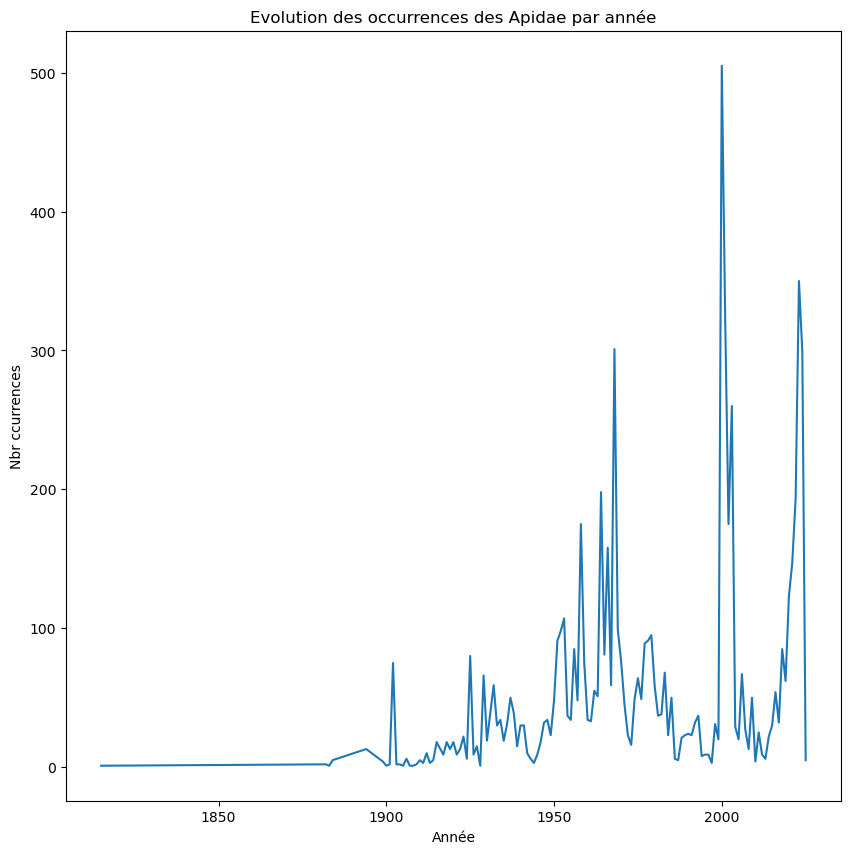

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df_gbif = pd.read_csv('occurence_data.csv', sep='\t', low_memory=False)

df_apidae = df_gbif[df_gbif['family'] == 'Apidae']
occ_by_year = df_apidae.groupby('year').size()

plt.figure(figsize=(10,10))
occ_by_year.plot(kind='line')
plt.title("Evolution des occurrences des Apidae par année")
plt.xlabel('Année')
plt.ylabel("Nbr ccurrences")
plt.show()

### Question 14
Après avoir tracé le nombre d’occurrences par année, on peut estimer une tendance générale en ajustant une régression linéaire (modules `scipy` (voir TP précédent) ou `sklearn`). Cette régression ne corrigera pas le biais des observations opportunistes, mais elle permet de visualiser une tendance approximative sur la période étudiée.
Générez la régression linéaire. Quelle est la tendance ? Pourquoi ?

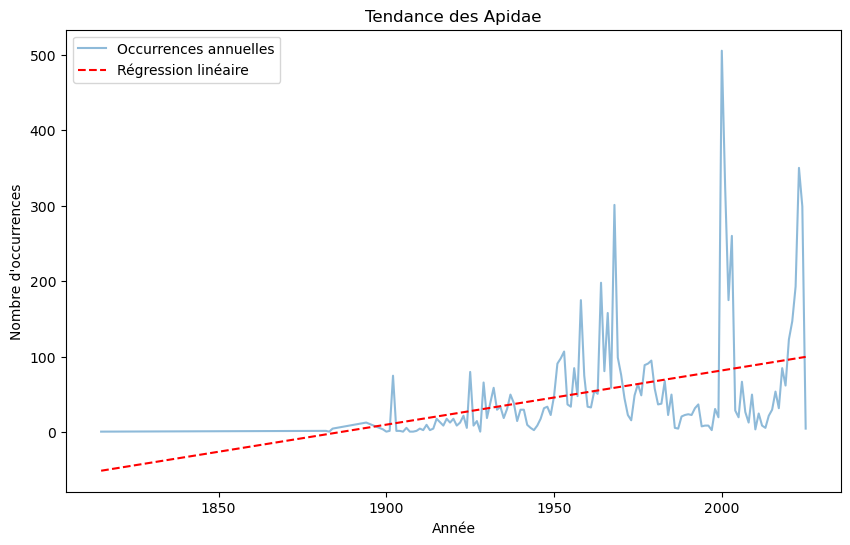

In [13]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import pandas as pd

# Charger les données
df = pd.read_csv('occurence_data.csv', sep='\t', low_memory=False)
df_apidae = df[df['family'] == 'Apidae']

# Nombre d'occurrences par année
occ_by_year = df_apidae.groupby('year').size().reset_index(name='n_occurrences')

# Préparer les variables pour la régression
X = occ_by_year['year'].values.reshape(-1, 1)
y = occ_by_year['n_occurrences'].values

# Ajuster le modèle
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)

# Tracer le graphique
plt.figure(figsize=(10,6))
plt.plot(occ_by_year['year'], occ_by_year['n_occurrences'], label='Occurrences annuelles', alpha=0.5)
plt.plot(occ_by_year['year'], y_pred, color='red', linestyle='--', label='Régression linéaire')
plt.xlabel('Année')
plt.ylabel('Nombre d\'occurrences')
plt.title('Tendance des Apidae')
plt.legend()
plt.show()

### Réponse question 14

La régression linéaire nous montre une tendance à la hausse du nombre d'occurrences. Cette hausse ne signifie pas que les populations d'Apidae augmentent. Elle s'explique dans un premier temps par principalement par l'essor des "sciences participatives" depuis les années 2000-2010, qui permet aux non-scientifiques de contribuer aux datasets des sites tels que GBIF ce qui a considérablement augmenté le nombre d'observations répertoriées. De plus, la numérisation des ressources des musées augmente également ce nombre d'observations.
Il s'agit donc d'un biais d'échantillonnage : plus il y a d'observateurs, plus il y a d'occurrences répertoriées, sans pour autant qu'il y ai une réelle évolution des populations.


## Questions optionnelles

### Question 15
Pour finir, vous allez visualiser la tendance globale de la biodiversité à partir du jeu de données BioTIME. Le fichier a été préalablement réduit et ne constitue pas le fichier intégral Chaque ligne du fichier correspond à une observation d’un taxon dans une année donnée.

Chargez le fichier  `biotime_echantillon.csv` dans un DataFrame avec pandas. Comptez le nombre d’occurrences par année en groupant les données par la colonne YEAR. Créez un graphique linéaire avec matplotlib :

L’axe des abscisses représente l’année (YEAR).

L’axe des ordonnées représente le nombre d’occurrences (nombre de taxons observés).

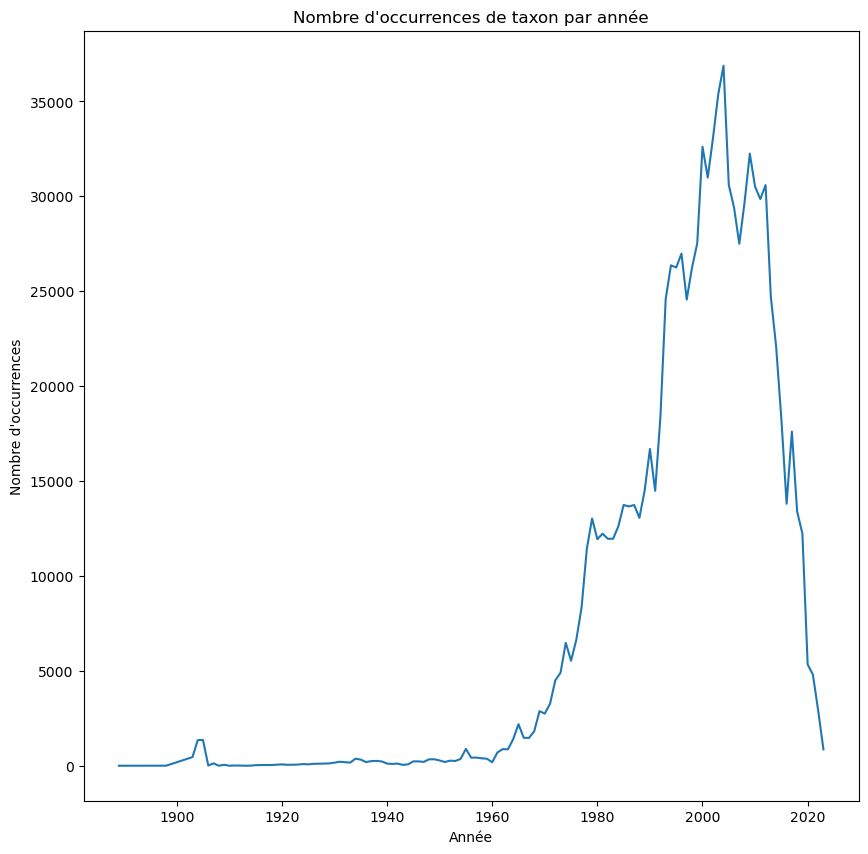

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

biotime = pd.read_csv("biotime_echantillon.csv")
occ_par_an = biotime.groupby('YEAR').size()
plt.figure(figsize=(10,10))
occ_par_an.plot(kind='line')
plt.title("Nombre d'occurrences de taxon par année")
plt.xlabel('Année')
plt.ylabel("Nombre d'occurrences")
plt.show()

### Question 16

Le graphique précédement généré n'est pas très informatif.
Nous aimerions représenter l'abondance de la biodiversité par taxon, et à partir de l'année 2000.

Refaites le graphique précédent mais en intégrant ces deux paramètres. 

Quels sont les groupes taxonomiques les plus en déclin ?

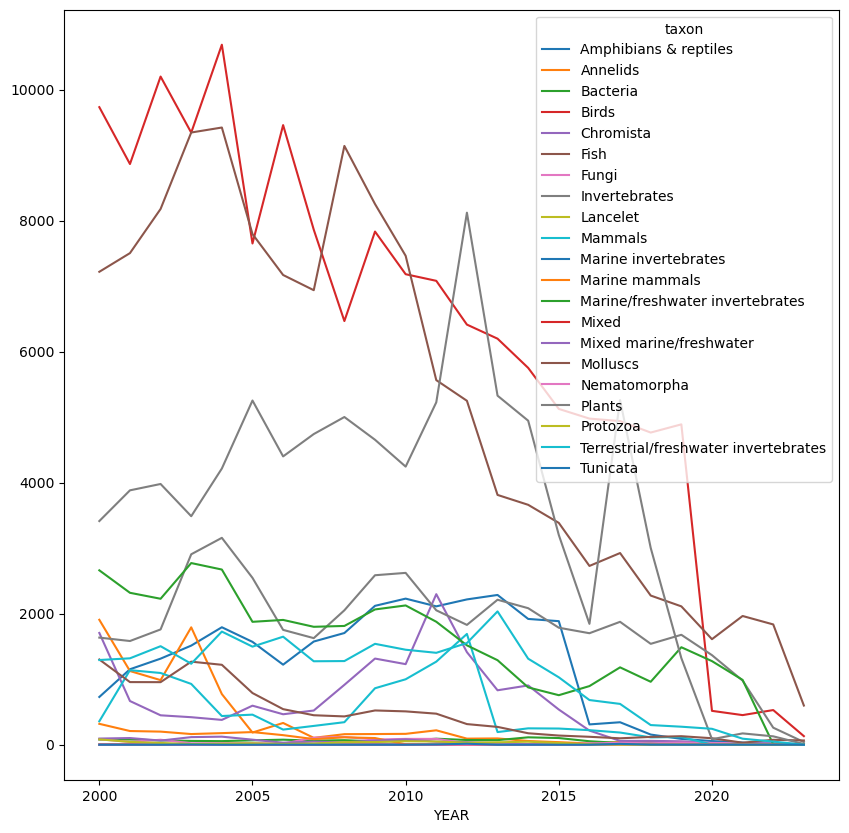

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

taxonomiq_col = [c for c in biotime.columns if c.lower() in ["taxa","class", "kingdom","phylum","taxon"]][0]

occ_taxonomiq_year = (biotime[biotime['YEAR'] >= 2000].groupby(['YEAR', taxonomiq_col]).size().unstack(fill_value=0))

occ_taxonomiq_year.plot(figsize=(10,10))
plt.show()

### Réponse question 16

D'après ce graphique, l'ensemble des groupes taxonomiques présentent une tendance à la baisse depuis 2000. Les invertébrés terrestres (molusques, insectes...) et des vertébrés comme les amphibiens ou les oiseaux subissent un fort déclin. Ces groupes sont particulièrement affectés par la destruction de leurs habitats naturels par l'usage des pesticides et le changement climatique.